In [1]:
import gymnasium as gym
from Q_learning import *
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import time


## Get familiar with the environment and see what is a random policy.

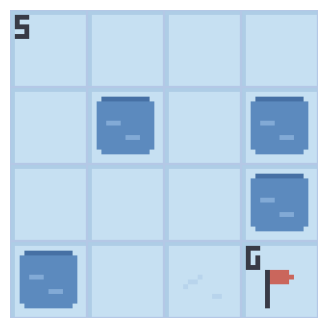

In [4]:
env = gym.make('FrozenLake-v1',map_name="4x4",render_mode='rgb_array')

for episode in range(5):
    current_observation, info = env.reset()
    episode_over = False

    while not episode_over:
        action=env.action_space.sample()
        new_observation, reward, terminated, truncated, info = env.step(action)

        current_observation=new_observation
        episode_over = terminated or truncated


        #### Visualization ####
        frame = env.render()
        clear_output(wait=True)
        plt.figure(figsize=(6, 4))
        plt.imshow(frame)
        plt.axis('off')
        display(plt.gcf())
        plt.close()
        time.sleep(0.2)
        #### Visualization ####

env.close()


## Train an agent with Q-learning

### Definition of the hyperparameters and creation of an agent (and a new environment)

In [2]:
n_episodes=50000
start_eps=1.0

display_train=100

In [3]:
env = gym.make('FrozenLake-v1',map_name="4x4")
env = gym.wrappers.RecordEpisodeStatistics(env, buffer_length=n_episodes)

agent=Agent_Q_learning(
    env=env,
    learning_rate=1e-2,
    start_epsilon=start_eps,
    epsilon_decay = start_eps / (n_episodes/2),
    final_epsilon=0.1,
    gamma=0.99
    )


### Training loop

In [4]:
count_update=0
Training_error=[]
Liste_epsilon=[]

for episode in range(n_episodes):
    current_observation, info = env.reset()
    episode_over = False

    while not episode_over:
        action=agent.eps_greedy_action(state=current_observation)
        new_observation, reward, terminated, truncated, info = env.step(action)

        TD_error=agent.update(
                                state=current_observation,
                               action=action,
                               next_state=new_observation, 
                               reward=reward,
                               terminated=terminated
                               )
        
        current_observation=new_observation
        episode_over = terminated or truncated



    epsilon=agent.update_epsilon()

    Training_error.append(TD_error)
    Liste_epsilon.append(epsilon)

    if (episode != 0 and episode%display_train==0):
        print(f"\nEpisode {episode} | TD_error = {np.mean(np.array(Training_error[-display_train:])):.6f}")
        print(f"Episode mean length: {np.array(env.length_queue)[-display_train:].mean()}")


agent.save_table("table_frozen_lake")
stat_train_return=env.return_queue
stat_train_lenght=env.length_queue
env.close()
print("\nTraining done")


Episode 100 | TD_error = 0.000000
Episode mean length: 7.41

Episode 200 | TD_error = 0.000000
Episode mean length: 7.25

Episode 300 | TD_error = 0.010000
Episode mean length: 7.52

Episode 400 | TD_error = 0.019998
Episode mean length: 7.95

Episode 500 | TD_error = -0.000005
Episode mean length: 6.75

Episode 600 | TD_error = 0.029405
Episode mean length: 7.25

Episode 700 | TD_error = 0.019648
Episode mean length: 7.57

Episode 800 | TD_error = 0.029384
Episode mean length: 8.37

Episode 900 | TD_error = 0.009560
Episode mean length: 8.51

Episode 1000 | TD_error = 0.009624
Episode mean length: 6.53

Episode 1100 | TD_error = 0.009420
Episode mean length: 7.46

Episode 1200 | TD_error = 0.009491
Episode mean length: 7.61

Episode 1300 | TD_error = 0.018887
Episode mean length: 7.26

Episode 1400 | TD_error = 0.037877
Episode mean length: 8.12

Episode 1500 | TD_error = -0.000188
Episode mean length: 7.53

Episode 1600 | TD_error = 0.009266
Episode mean length: 7.76

Episode 1700 |

### Visualization of the training (copyright from Gymnasium)

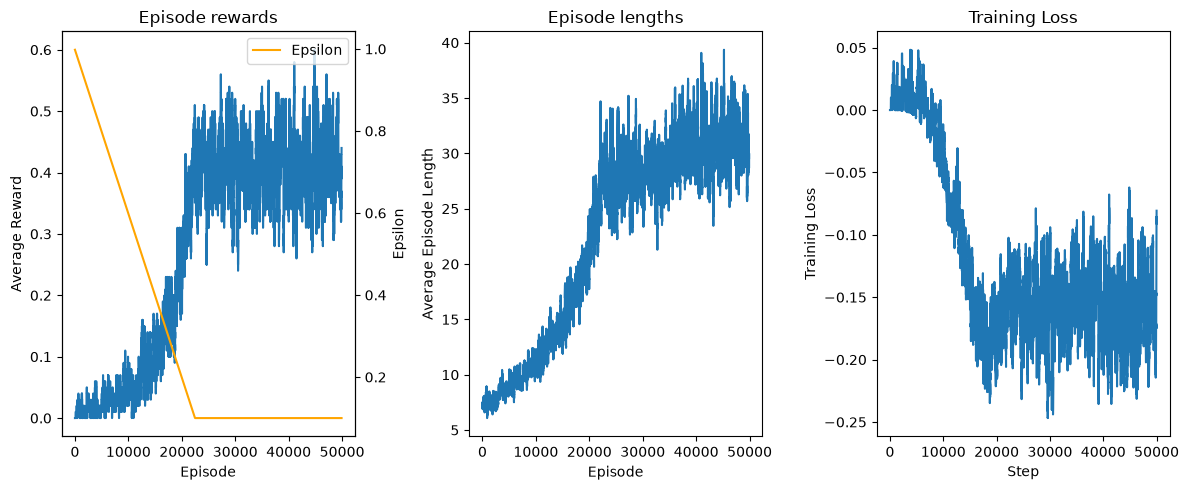

In [5]:
def get_moving_avgs(arr, window, convolution_mode):
    """Compute moving average to smooth noisy data."""
    return np.convolve(
        np.array(arr).flatten(),
        np.ones(window),
        mode=convolution_mode
    ) / window

# Smooth over a 500-episode window
rolling_length = display_train
fig, axs = plt.subplots(ncols=3, figsize=(12, 5))

# Episode rewards (win/loss performance)
axs[0].set_title("Episode rewards")
reward_moving_average = get_moving_avgs(
    stat_train_return,
    rolling_length,
    "valid"
)

epsilon_moving_avg=get_moving_avgs(
    Liste_epsilon,
    rolling_length,
    "valid"
)

x = range(len(reward_moving_average))
axs[0].plot(x, reward_moving_average, label="Average Reward")
axs[0].set_ylabel("Average Reward")
axs[0].set_xlabel("Episode")

# Axe Y droit : Epsilon
ax_epsilon = axs[0].twinx()
ax_epsilon.plot(x, epsilon_moving_avg, color="orange", label="Epsilon")
ax_epsilon.set_ylabel("Epsilon")
ax_epsilon.legend(loc="upper right")

# Episode lengths (how many actions per hand)
axs[1].set_title("Episode lengths")
length_moving_average = get_moving_avgs(
    stat_train_lenght,
    rolling_length,
    "valid"
)
axs[1].plot(range(len(length_moving_average)), length_moving_average)
axs[1].set_ylabel("Average Episode Length")
axs[1].set_xlabel("Episode")

# Training error (how much we're still learning)
axs[2].set_title("Training Loss")
training_loss_moving_average = get_moving_avgs(
    Training_error,
    rolling_length,
    "same"
)
axs[2].plot(range(len(training_loss_moving_average)), training_loss_moving_average)
axs[2].set_ylabel("Training Loss")
axs[2].set_xlabel("Step")

plt.tight_layout()
plt.show()

## Let's test the agent !

### We load a new environment and we get a previous trained agent

In [2]:
env = gym.make('FrozenLake-v1',map_name="4x4",render_mode='rgb_array')
agent_test=Agent_Q_learning(
    env=env,
    learning_rate=None,
    start_epsilon=None,
    epsilon_decay =None,
    final_epsilon=None,
    gamma=None,
    table_directory="models/table_frozen_lake.pkl"
    )



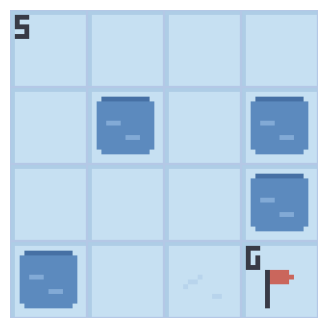

total_reward Episode 4: 0


In [3]:

for episode in range(5):
    current_observation, info = env.reset()

    episode_over = False
    total_reward = 0

    while not episode_over:
        action=agent_test.best_action(current_observation)
        new_observation, reward, terminated, truncated, info = env.step(action)

        current_observation=new_observation
        episode_over = terminated or truncated

        total_reward += reward

        #### Visualization ####
        frame = env.render()
        clear_output(wait=True)
        plt.figure(figsize=(6, 4))
        plt.imshow(frame)
        plt.axis('off')
        display(plt.gcf())
        plt.close()
        time.sleep(0.2)
        #### Visualization ####

    print(f"total_reward Episode {episode}:",total_reward)
    

env.close()

